In [1]:
!pip install --upgrade binance-historical-data plotly -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 41.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 272.8/272.8 kB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 37.3 MB/s eta 0:00:00


In [2]:
import os
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime, timedelta, date, time
from binance_historical_data import BinanceDataDumper
warnings.filterwarnings('ignore')

def get_list_all_trading_pairs():
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",  # spot, um, cm
        data_type="klines",  # aggTrades, klines, trades
        data_frequency="5m",
    )
    return data_dumper.get_list_all_trading_pairs()

def detect_timestamp_unit(timestamp):
    num_digits = len(str(timestamp))
    if num_digits == 13:
        return 'ms'
    elif num_digits == 16:
        return 'us'
    else:
        raise ValueError(f"Timestamp không hợp lệ: {timestamp}")

def convert_timestamp(timestamp):
    unit = detect_timestamp_unit(timestamp)
    return pd.to_datetime(timestamp, unit=unit, errors='coerce')

def download_ticker(ticker, date_start, date_end, data_frequency="1h"):
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",
        data_type="klines",
        data_frequency= data_frequency,
    )
    date_start = datetime.strptime(date_start, "%Y-%m-%d").date()
    date_end = datetime.strptime(date_end, "%Y-%m-%d").date()
    data_dumper.dump_data(
        tickers = ticker,
        date_start = date_start,
        date_end = date_end,
        is_to_update_existing = False,
    )

def read_csv_file(file_path):
    df = pd.read_csv(file_path)
    df.columns = [
        "open_time", "Open", "High", "Low", "Close", "volume",
        "close_time", "quote_asset_volume", "number_of_trades",
        "taker_buy_base_asset_volume", "taker_buy_quote_asset_volume", "ignore"
    ]
    df['open_time'] = df['open_time'].apply(convert_timestamp)
    df['close_time'] = df['close_time'].apply(convert_timestamp)
    return df

def get_csv_files(directory):
    try:
        if not os.path.exists(directory):
            print(f"Warning: Thư mục không tồn tại: {directory}")
            return []
        return [os.path.join(directory, f) for f in os.listdir(directory) if f.endswith('.csv')]
    except Exception as e:
        print(f"Lỗi khi đọc thư mục {directory}: {str(e)}")
        return []

# Load data from file
def process_csv_files(ticker, data_frequency = "1h"):
    daily_path = os.path.join(os.getcwd(), f"spot/daily/klines/{ticker}/{data_frequency}")
    monthly_path = os.path.join(os.getcwd(), f"spot/monthly/klines/{ticker}/{data_frequency}")
    daily_files = get_csv_files(daily_path)
    monthly_files = get_csv_files(monthly_path)
    all_files = daily_files + monthly_files
    if not all_files:
        print(f"❗ Không có file CSV nào cho {ticker}")
        return None
    data = pd.concat([read_csv_file(file) for file in all_files], ignore_index=True)
    data.sort_values(by='open_time', inplace=True)
    return data



In [3]:
ticker = 'BTCUSDT'
data_frequency = '1m'
download_ticker(ticker, "2025-01-01", "2025-05-01", data_frequency)
df = process_csv_files(ticker, data_frequency)
df = df.drop(columns=['close_time',	'quote_asset_volume',	'number_of_trades',	'taker_buy_base_asset_volume',	'taker_buy_quote_asset_volume',	'ignore'])
df.set_index('open_time', inplace=True)
df

---> Found overall tickers: 601
---> Filter to asked tickers: 7
------> Tickers left: 2
Download full data for 2 tickers: 
---> Data will be saved here: /content/spot
---> Data Frequency: 1m
---> Start Date: 20250101
---> End Date: 20250501


Tickers:   0%|          | 0/2 [00:00<?, ?it/s]

monthly files to download:   0%|          | 0/4 [00:00<?, ?files/s]

daily files to download:   0%|          | 0/1 [00:00<?, ?files/s]

monthly files to download: 0files [00:00, ?files/s]

daily files to download: 0files [00:00, ?files/s]

Tried to dump data for 2 tickers:
---> For BTCUSDT new data saved for: 4 months 1 days
---> For BTCUSD new data saved for: 0 months 0 days


,Open,High,Low,Close,volume
open_time,,,,,
2025-01-01 00:01:00,93610.93,93652.00,93606.20,93652.00,12.14029
2025-01-01 00:02:00,93652.00,93702.15,93635.98,93702.15,11.60597
2025-01-01 00:03:00,93702.14,93702.15,93654.48,93677.98,8.72958
2025-01-01 00:04:00,93677.98,93677.99,93659.92,93661.20,5.24749
2025-01-01 00:05:00,93661.20,93678.02,93661.20,93678.01,5.08788
...,...,...,...,...,...
2025-05-01 23:55:00,96452.38,96460.00,96442.73,96459.99,4.06135
2025-05-01 23:56:00,96460.00,96500.00,96459.99,96500.00,6.17950
2025-05-01 23:57:00,96500.00,96500.00,96485.01,96485.01,2.75048


In [20]:
# Calculate moving average for prices
short_window = 20    #Adjust params here
long_window = 50
df['MA_long'] = df['Close'].rolling(window=long_window).mean()
df['MA_short'] = df['Close'].rolling(window=short_window).mean()

# Position
df['Position'] = np.select((
    (df['MA_short'] > df['MA_long']) & (df['MA_short'].shift(1) < df['MA_long'].shift(1)),
    (df['MA_short'] < df['MA_long']) & (df['MA_short'].shift(1) > df['MA_long'].shift(1))),
                           (1, -1),
                           default=0)

df.head(100)

,Open,High,Low,Close,volume,MA_long,MA_short,Position,Pnls
open_time,,,,,,,,,
2025-01-01 00:01:00,93610.93,93652.00,93606.20,93652.00,12.14029,NaN,NaN,0,0.0
2025-01-01 00:02:00,93652.00,93702.15,93635.98,93702.15,11.60597,NaN,NaN,0,0.0
2025-01-01 00:03:00,93702.14,93702.15,93654.48,93677.98,8.72958,NaN,NaN,0,0.0
2025-01-01 00:04:00,93677.98,93677.99,93659.92,93661.20,5.24749,NaN,NaN,0,0.0
2025-01-01 00:05:00,93661.20,93678.02,93661.20,93678.01,5.08788,NaN,NaN,0,0.0
...,...,...,...,...,...,...,...,...,...
2025-01-01 01:36:00,93893.30,93944.80,93893.30,93944.80,5.38613,94048.9000,93923.8715,0,0.0
2025-01-01 01:37:00,93944.79,93953.98,93931.04,93935.53,4.12658,94048.4108,93921.5375,0,0.0
2025-01-01 01:38:00,93935.53,93935.54,93935.53,93935.54,4.33278,94047.5622,93919.3670,0,0.0


In [21]:
## --- CALCULATE PNLS WITH STOP LOSS - TAKE PROFIT ---
def calculate_pnls (pos, close):
  entry_price = 0
  pnls = []
  fee = 0.05/100

  for i in range (len(pos)):
    std = 7690
    loss = - std
    gain = 2*std
    if pos[i] != 0:
      if pos[i-1] == 0:
        entry_price = close[i]
        pnls.append (-entry_price * fee)
      elif pos[i-1] !=0:
        pnls.append ((close[i] - entry_price)*pos[i-1]*(1-fee) - close[i] * fee)
      entry_price = close[i]

    elif pos[i] == 0 and entry_price != 0:
      pos [i] = pos[i-1]
      returns = (close[i] - entry_price)*pos[i]
      if returns >= gain or returns <= loss:
        pnls.append (returns*(1-fee))
        entry_price = 0
      else:
        pnls.append (0)
    else:
      pnls.append (0)

  return pos, pnls


df['Position'], df['Pnls'], = calculate_pnls (df['Position'], df['Close'])

df.head(300)


,Open,High,Low,Close,volume,MA_long,MA_short,Position,Pnls
open_time,,,,,,,,,
2025-01-01 00:01:00,93610.93,93652.00,93606.20,93652.00,12.14029,NaN,NaN,0,0.0
2025-01-01 00:02:00,93652.00,93702.15,93635.98,93702.15,11.60597,NaN,NaN,0,0.0
2025-01-01 00:03:00,93702.14,93702.15,93654.48,93677.98,8.72958,NaN,NaN,0,0.0
2025-01-01 00:04:00,93677.98,93677.99,93659.92,93661.20,5.24749,NaN,NaN,0,0.0
2025-01-01 00:05:00,93661.20,93678.02,93661.20,93678.01,5.08788,NaN,NaN,0,0.0
...,...,...,...,...,...,...,...,...,...
2025-01-01 04:56:00,93649.00,93669.99,93648.99,93669.98,5.39030,93685.0092,93644.6895,-1,0.0
2025-01-01 04:57:00,93669.98,93669.99,93669.98,93669.98,1.37790,93683.1478,93646.4680,-1,0.0
2025-01-01 04:58:00,93669.99,93669.99,93597.00,93597.01,9.42466,93680.0280,93644.0190,-1,0.0


In [6]:
# ## --- CALCULATE PNLS WITHOUT STOP LOSS - TAKE PROFIT ---

# def calculate_returns(pos,close):
#   entry = [0] * len(pos)
#   pnls = [0] * len(pos)
#   fee = 0.05/100
#   for i in range (1,len(pos)):
#     if pos[i] == pos[i-1]:
#       entry[i] = entry[i-1]
#     elif pos[i] != pos[i-1]:
#       entry[i] = close[i]

#   for i in range (1,len(pos)):
#     if entry[i] != entry[i-1]:
#       pnls[i] = (entry[i] - entry[i-1])*pos[i-1]*(1-fee)

#   return entry, pnls


# df['Position'] = df['Position'].replace(0, method='ffill')
# df['Price'], df['Pnls'] = calculate_returns(df['Position'], df['Close'])


# df.tail (500) # Display the DataFrame

In [22]:
count_positive = (df['Pnls'] > 0).sum()
sum_positive = df[df['Pnls'] > 0]['Pnls'].sum()

count_negative = (df['Pnls'] < 0).sum()
sum_negative = df[df['Pnls'] < 0]['Pnls'].sum()

print(f'Số lệnh lãi: {count_positive}')
print(f'Số lệnh lỗ: {count_negative}')
print(f'Tổng lãi: {sum_positive}')
print(f'Lãi trung bình: {sum_positive/count_positive}')
print(f'Tổng lỗ: {sum_negative}')
print(f'Lỗ trung bình: {sum_negative/count_negative}')

Số lệnh lãi: 1124
Số lệnh lỗ: 2916
Tổng lãi: 425234.1229450003
Lãi trung bình: 378.32217343861237
Tổng lỗ: -639422.421165
Lỗ trung bình: -219.28066569444442


In [23]:
def longest_negative_streak(data):
    current = []
    count_list = []
    total_list = []
    # average = []      # Dùng numpy để tính cái này sau
    total = 0
    count = 0
    longest_count = 0
    highest_sum = 0

    for num in data:
        if num < 0:
            current.append(num)
        else:
            if current != []:
                count = len(current)
                total = sum(current)
                count_list.append(count)
                total_list.append(total)
                if abs(total) > abs(highest_sum):
                  highest_sum = total
                if count > longest_count:
                  longest_count = count
                  longest = current

                current = []
                count = 0
                total = 0

    return max(count_list), highest_sum, longest


pnls = df['Pnls'].tolist()
pnls_no_0 = [x for x in pnls if x != 0]

count, highest_sum, longest_streak = longest_negative_streak(pnls_no_0)

print(f'Highest sum streak: {highest_sum}')
print(f'Longest streak: {count}')
print(f'Longest streak: {longest_streak}')


Highest sum streak: -7225.063754999992
Longest streak: 26
Longest streak: [-120.14903000000349, -91.30798499999884, -72.9817900000064, -45.41714500000466, -2.3087299999959257, -151.87871999999243, -144.08168499999243, -28.932594999995345, -182.71535500000294, -124.37562999999943, -126.62226999999302, -0.8544849999953428, -28.977044999999997, -115.5604199999965, -121.63762999999186, -172.04736000000176, -37.397165000000584, -112.84471999999766, -155.56664000000058, -15.633319999995347, -21.161114999999416, -40.01056, -132.47912499999768, -91.91427999999709, -110.51078999999652, -65.33496000000466]


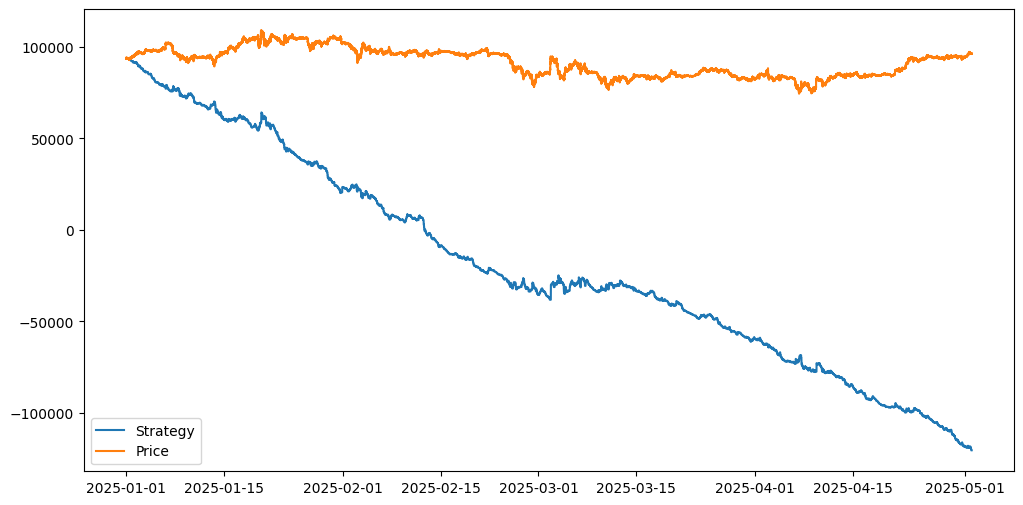

In [24]:
dates = df.index.tolist()
plt.figure(figsize=(12,6))

# Plot profit
# plt.plot(unrealised_dates, np.cumprod(1+np.array(unrealised))-1)
# plt.plot(dates, np.cumprod(1+np.array(pnls))-1)
#plt.plot(dates,np.cumprod(1+np.array(pnls))-1)
# plt.plot(unrlzd_dates,np.cumprod(1+np.array(unrlzd)))
plt.plot(dates, np.cumsum(pnls)+df['Close'][0], label='Strategy')
plt.plot(dates, df['Close'], label='Price')
plt.legend()
plt.show()

#plt.plot(unrlzd_dates, np.cumsum(unrlzd))

In [10]:
### --- CALCULATE PNLS WITH STOP LOSS - TAKE PROFIT ---

# def entry_price (pos, close):
#   entry = [0] * len(pos)
#   for i in range (1,len(pos)):
#     if pos[i] != 0:
#       entry[i] = close[i]
#     if pos[i] == 0:
#       entry[i] = entry[i-1]
#   return entry

# def set_SL_TP_vectorized(df):
#     std = df['Close'].rolling(window=20).std()
#     loss = std
#     gain = 2*std

#     # Calculate SL and TP based on position using np.where for vectorization
#     SL = np.select(
#         (df['Position'] == 1, df['Position'] == -1, df['Position'] == 0),
#         (df['Price'] - loss, df['Price'] + loss, 0))

#     TP = np.select(
#         (df['Position'] == 1, df['Position'] == -1, df['Position'] == 0),
#         (df['Price'] + gain, df['Price'] - gain, 0))

#     return SL, TP, std

# def calculate_pnls (df):
#   fee = 0.05/100

#   for i in range (1, len(df['Position'])):
#     if df['Close'][i] <= df['SL'][i] or df['Close'][i] == df['TP'][i]:
#       df['Pnls'][i] = (df['Close'][i] - df['Price'][i])*df['Position'][i]*(1-fee)
#   return df


# df['Price'] = entry_price(df['Position'], df['Close'])

# df['SL'], df['TP'], df['Std'] = set_SL_TP_vectorized(df)

# df['SL'] = df['SL'].replace(0, method='ffill')
# df['TP'] = df['TP'].replace(0, method='ffill')

# df.head(300)



In [18]:
np.std(df['Close'])

7609.0168681856